## 1. Data Ingestion and Preprocessing

In this section, we import the raw historical data from **Station 1413** and format it for subsequent time-series analysis. 

### Key Actions Performed:
* **File Ingestion:** Loaded the Excel spreadsheet while skipping the first row (`skiprows=1`) to filter out the file's main title and isolate the data table header.
* **Column Renaming:** Standardized headers to clean, concise English names (`datetime` and `q_m3s` for flow rate in cubic meters per second) to streamline data manipulation.
* **Datetime Normalization:** Converted the string timestamps into actual datetime objects using the specific format `%d/%m/%Y %H:%M`. We then applied `.dt.normalize()` to strip away the hourly timestamps (e.g., setting hours to `00:00`), keeping only the calendar date.
* **Data Verification:** Printed basic dataset structures, dimensions, and date ranges to ensure accuracy. 

> **Note on Data Completeness:** The total row count represents the length of the dataset matrix. It confirms the structure is loaded, but does not guarantee every calendar day within the period contains valid, non-null measurements.


In [1]:
import pandas as pd 

# Load raw dataset and fix headers
raw = pd.read_excel("../data/raw/Historicos-Estacion 1413.xlsx", skiprows=1)
raw.columns = ["datetime", "q_m3s"]

# Parse and normalize timestamps to daily dates
raw["date"] = pd.to_datetime(raw["datetime"], format="%d/%m/%Y %H:%M").dt.normalize() 

# Metadata and formatting check
raw.info() 
display(raw.head())   

# Temporal range and structural properties
print('First recorded date: ', raw["date"].min())
print('Last recorded date: ', raw["date"].max())
print("Rows:", len(raw))

<class 'pandas.DataFrame'>
RangeIndex: 25464 entries, 0 to 25463
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   datetime  25464 non-null  str           
 1   q_m3s     25464 non-null  float64       
 2   date      25464 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 596.9 KB


,datetime,q_m3s,date
0,01/07/1956 09:00,17.0,1956-07-01
1,02/07/1956 09:00,17.0,1956-07-02
2,03/07/1956 09:00,17.0,1956-07-03
3,04/07/1956 09:00,18.0,1956-07-04
4,05/07/1956 09:00,19.0,1956-07-05


First recorded date:  1956-07-01 00:00:00
Last recorded date:  2026-06-30 00:00:00
Rows: 25464


## 1.1 Time-series continuity and quality control

To assess the integrity of our historical records, we evaluate the dataset's continuity. We calculate the expected number of calendar days between the first and last recorded dates and cross-reference this against our row count to detect missing time-steps. Additionally, we need to check two things:
 1) We look for zero or negative values in column 'q_m3s': An error in the flow sensor could trigger a negative value, which is impossible.
 2) We look for repeated dates in column 'date': If there are repeated dates in said column, this would underestimate the actual number of missing days.

### Key Actions Performed:
* **Expected days:** Total number of calendar days spanned in the dataset.
* **Missing days:** The difference between the expected calendar days and the actual number of rows.
* **Repeated dates:** A repeated date could occupy the place of a missing date, underestimating the actual number of missing days. 
* **Percentage of missing days:** It is interesting to check this value, in order to determine if the raw dataset has a high number of missing days. 



In [2]:
# Determine the expected calendar days spanned
expected_days = (raw["date"].max() - raw["date"].min()).days + 1
print("Expected days:", expected_days)

# Determine the number of missing days
missing_days = expected_days - len(raw)
print("Missing days:", missing_days)

# Check if there are zero or negative values in column 'q_m3s'.
print("Zero or negative values:", (raw["q_m3s"] <= 0).sum())

# Check if there are duplicated dates in column 'date'
print("Duplicated dates:", raw["date"].duplicated().sum())

# Calculate the final percetange of missing days
print("Percentage of missing days:", round(missing_days/expected_days * 100,3), '%')


Expected days: 25567
Missing days: 103
Zero or negative values: 0
Duplicated dates: 0
Percentage of missing days: 0.403 %


## 1.2 Locating and sorting missing days 

After calculating the number of expected, missing, zero or negative and duplicated days, now it is necessary to determine where those missing days are located. In order to achieve this, we will create a range named 'full_calendar' which goes from the 1st to the last date recorded, with a frequency of 1 day. Then, we will determine the number of missing dates (stored in 'missing_dates'). After this, we check if the previous value stored in 'missing_days' (calculated doing: expected_days - len(raw)) equals missing_dates (obtained with the "range method").
Finally, we count and organize the missing dates, sorting them by year. 

### Key Actions Performed:
* **Range:** We create a range stored in 'full_calendar', that goes from the 1st to the last date, and with a daily frequency.
* **Quantity of missing dates:** Even though we already calculated the number of missing dates doing (expected_days - len(raw)), we need to check if the quantity of missing dates coming from both methods ("difference and range" methods) are the same.
* **Number of missing dates per year:** From all the missing dates obtained previously, we classify them by the year those "missing spaces" are located. 



In [3]:
# Create a range with start and end point, and frequency
full_calendar = pd.date_range(start= raw["date"].min() , end= raw["date"].max() ,freq= '1D')

# Identify the missing dates and obtain the quantity
missing_dates=full_calendar[~full_calendar.isin(raw['date'])]
print(missing_dates)
print('Quantity of missing dates: ',len(missing_dates))

# Check is missing_dates == missing_days
if len(missing_dates) == missing_days:
    print('Both values are equal')
else:
    print('Values are not equal ')

# Sort the missing dates by year
missing_dates.year.value_counts().sort_index()

DatetimeIndex(['1962-09-01', '1962-09-02', '1962-09-03', '1962-09-04',
               '1962-09-05', '1962-09-06', '1962-09-07', '1962-09-08',
               '1962-09-09', '1962-09-10',
               ...
               '1985-06-22', '1985-06-23', '1985-06-24', '1985-06-25',
               '1985-06-26', '1985-06-27', '1985-06-28', '1985-06-29',
               '1985-06-30', '2023-06-18'],
              dtype='datetime64[us]', length=103, freq=None)
Quantity of missing dates:  103
Both values are equal


1962    30
1970     2
1976    40
1985    30
2023     1
Name: count, dtype: int64

## 1.3 Interpolating missing days 

After locating and sorting the missing days, we need to use a linear interpolation model to fill the flow values of the missing dates (in other words, filling the "q_m3s values" of the missing dates). To achieve this, we follow the sequence:
 1) We define series "q" which makes the column 'date' the index of the table. 
 2) After, we force the table to have exactly the rows of a given index (using 'reindex'), which makes the missing dates to appear as 'NaN'. 
 3) The fact that the missing dates appear as 'NaN' is useful to create a flag called 'filled' which has 2 possible values: True / False. Incorporating a flag is necessary to differentiate the 'filled' values from the 'measured data'.
 4) Finally, we check the following:  A) There is 0 NaN after interpolating ; B) There are 103 filled dates ; C) Visual inspection of the filled gap [in this particular case: 1976-06-18:1976-08-02]

### Key Actions Performed:
* **Set index:** We define a series 'q' that correlates the values in column 'q_m3s' with the new index: 'date'.
* **Reindex:** By forcing the table to have exactly the rows of a given index, the rows related with the missing dates are created, and 'NaN' appears in them.
* **Interpolate:** Allows us to use a linear interpolation model to fill the flow values of the missing dates. We use the 'time' method, which interpolates based on the distance between the dates.



In [4]:
# Define series 'q' , which correlates the values in column 'q_m3s' with the new index: 'dates'
q = raw.set_index("date")["q_m3s"]

# Use reindex to generate the rows related with the missing dates
q = q.reindex(full_calendar)

# Create the flag 'filled' to recognize if the value is measured or interpolated
filled = q.isna()

# Use 'time' method for linear interpolation
q=q.interpolate(method="time")
print(q)    

# Verifications: 
print("NaN after interpolation:", q.isna().sum())   # must be 0 [means all NaN have been filled]
print("Filled days:", filled.sum())                  # must be 103 [missing dates]
display(q["1976-06-18":"1976-08-02"])                # look inside the longest gap to check if the interpolation was executed

1956-07-01    17.00
1956-07-02    17.00
1956-07-03    17.00
1956-07-04    18.00
1956-07-05    19.00
              ...  
2026-06-26    22.17
2026-06-27    22.14
2026-06-28    21.37
2026-06-29    21.72
2026-06-30    21.66
Freq: D, Name: q_m3s, Length: 25567, dtype: float64
NaN after interpolation: 0
Filled days: 103


1976-06-18    16.800000
1976-06-19    17.000000
1976-06-20    17.200000
1976-06-21    17.200000
1976-06-22    17.187805
1976-06-23    17.175610
1976-06-24    17.163415
1976-06-25    17.151220
1976-06-26    17.139024
1976-06-27    17.126829
1976-06-28    17.114634
1976-06-29    17.102439
1976-06-30    17.090244
1976-07-01    17.078049
1976-07-02    17.065854
1976-07-03    17.053659
1976-07-04    17.041463
1976-07-05    17.029268
1976-07-06    17.017073
1976-07-07    17.004878
1976-07-08    16.992683
1976-07-09    16.980488
1976-07-10    16.968293
1976-07-11    16.956098
1976-07-12    16.943902
1976-07-13    16.931707
1976-07-14    16.919512
1976-07-15    16.907317
1976-07-16    16.895122
1976-07-17    16.882927
1976-07-18    16.870732
1976-07-19    16.858537
1976-07-20    16.846341
1976-07-21    16.834146
1976-07-22    16.821951
1976-07-23    16.809756
1976-07-24    16.797561
1976-07-25    16.785366
1976-07-26    16.773171
1976-07-27    16.760976
1976-07-28    16.748780
1976-07-29    16

## 1.4 Plotting historical data

In this section, we import the matplotlib library and plot the date vs daily mean flow (m3/s) to visualize the historical data.

### Key Actions Performed:
* **Import Matplotlib:** Matplotlib is an open-source library for creating interactive data visualization resources. 
* **Fig parameters:** 14x4 fig size: wide format for a long series.
* **Data parameters:** There are 2 kind of points: A) Measured points (in blue, united by a line). B) Interpolated points (in red, shown as single points).
* **Axes:** 2 axes: 'Date' as the horizontal axis, and 'Daily mean flow (m³/s)' as the vertical axis
* **Rest of parameters:** Such as the plot title and legends.

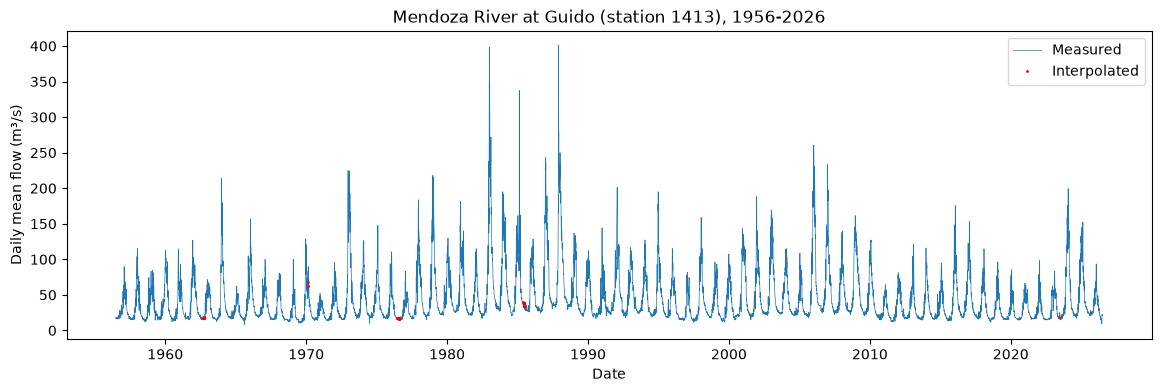

In [5]:
# Import matplotlib
import matplotlib.pyplot as plt

# Creating the graph
fig, ax = plt.subplots(figsize=(14,4))

# Define both kind of values, measured and interpolated
ax.plot(q.index, q, linewidth=0.5, label="Measured")
ax.plot(q[filled].index, q[filled], ".", color="red", markersize=2, label="Interpolated")

# Name both axes
ax.set_xlabel("Date")
ax.set_ylabel("Daily mean flow (m³/s)")

# Define set title and legend
ax.set_title("Mendoza River at Guido (station 1413), 1956-2026")
ax.legend()

# Show graph
plt.show()

## 1.5 Determining wet and dry years

In this section, we determine various and useful parameters such as the means and medians of the different individual years and decades.
First, we obtain the annual average flow rate (mean), strictly from the complete calendar years (the first and last year,which are incomplete, will not be taken in account). Then, we sort those average flow rates and select the 5 wettest years.

After this, we can also calculate the mean of each decade and also sort these values. This will also give us useful information regarding the dry and wet decades. Added to this, the median of the average flow rates will be used as a threshold to determine if a particular year is considered as dry or wet. This means that we are going to be using our own criteria: If the average flow rate is less than the previously obtained median (lower half of the 69 average flows), the year will be considered as dry. Otherwise, it will be considered as wet. 

### Key Actions Performed:
* **Annual average flow rate, based on complete years:** For each complete year, the average flow rate is calculated. For the years at the ends of the series, it does not make sense to calculate the average flow rate.
* **Average flow rate per decade:** In the same way that the average flow rate was calculated for each full year, the same process is applied to the decades. This allows us to determine which decades are dry and which are wet.
* **median as a threshold and for dry/wet classification:** As previously explained, the median of the annual average flow rates is used as a threshold to determine whether a given year is dry or wet. If a year falls below this median, it is considered to be in the "first half" of the data and is therefore classified as a dry year. Otherwise, it is considered a wet year.




In [6]:
# Determining and interpreting the wet and dry years

    # Determining the mean of the individual years and decades
annual_mean = q.groupby(q.index.year).mean() # mean flow of each calendar year
annual_mean = annual_mean.loc[1957:2025]   # keep complete calendar years only -> does not consider incomplete years
display('5 WETTEST YEARS:',annual_mean.sort_values(ascending=False).head(5)) # 5 wettest years
display('5 DRIEST YEARS:',annual_mean.sort_values(ascending=True).head(5)) # 5 driest years

decade_mean = annual_mean.groupby((annual_mean.index // 10)*10).mean()  # Determine the mean flow for each decade
display('MEAN FLOW BY DECADE:',decade_mean.sort_values(ascending=False).round(1))  # mean flow by decade

    # Determining the median of the annual averages.
median_flow = annual_mean.median() # median calculated from the 69 annual means. "central" mean
print("Median annual flow, threshold:", round(median_flow, 1))

dry_years = annual_mean[annual_mean < median_flow]   # Create a list and keep only the years below the median
print("Dry years:", dry_years.index.tolist())  # Print only the dry years, to count them

'5 WETTEST YEARS:'

1983    90.839726
1987    87.958329
2006    73.122712
1988    72.665738
1984    64.765191
Name: q_m3s, dtype: float64

'5 DRIEST YEARS:'

1971    25.873699
1968    26.699180
2022    27.351973
2021    27.967726
2011    28.431616
Name: q_m3s, dtype: float64

'MEAN FLOW BY DECADE:'

1980    64.4
2000    53.3
1990    42.4
1970    40.6
2020    37.9
2010    35.3
1960    35.0
1950    33.6
Name: q_m3s, dtype: float64

Median annual flow, threshold: 40.6
Dry years: [1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1967, 1968, 1969, 1970, 1971, 1972, 1975, 1976, 1990, 1996, 1997, 1999, 2004, 2010, 2011, 2012, 2013, 2014, 2015, 2018, 2019, 2020, 2021, 2022, 2023]


### Interpretation
1)  Peaks clearly occur in warmer seasons: the line starts rising in spring (September to December) and presents its highest peaks in summer (January to March). This corresponds completely with the fact that river discharge depends primarily on seasonal snowmelt, while the remainder comes from glacial melt and rainfall, as stated by Pensado (2016) and Salomón et al. (2005), and cited in "Análisis de Factibilidad de Fondo de Agua en la Cuenca del Río Mendoza", p. 13. 

2) The 5 wettest years are: 1983 (with an average flow rate of 90.8 m3/s) ; 1987 (with an average flow rate of 88.0 m3/s) ; 2006 (with an average flow rate of 73.1 m3/s) ; 1988 (with an average flow rate of 72.7 m3/s) ; 1984 (with an average flow rate of 64.8 m3/s). We can also analyze the driest year which is 1971 (with an average flow rate of 25.9 m3/s)

3) When comparing the period from 2010 to 2020 with other decades, the average for the 2010s (35.3) is almost the same as that of the 1960s (35.0). The 2010s were dry, but comparable to the 1960s. 
Using our own criteria, we can see that there is a streak of 6 dry years between 2010 and 2015, and there is another streak of 6 consecutive dry years between 2018 and 2023. 
It is worth noting that a stretch of dry years is not a unique feature of the 2010–2020 decade. Other decades exhibit this same pattern: 
    A) 1957–1972 contains 15 dry years out of 16; only 1966 is above the median. 
    B) The 1957 streak starts at the beginning of the record, so its true length may be longer.
    C) From 1967 to 1972, there is another such sequence, lasting 6 years.

4) Regarding interpolation:  interpolated points (in red) show logical values, with no outliers. 

## 1.6 Determining hydrological years

In this section, we will determine the hydrological year (October–September). the raw data runs from July 1956 to June 2026.
First, the hydrological years will be identified by the year in which they end.
Next, we will verify the number of days in each hydrological year, ensuring that each hydrological year contains 365 (or 366) days. It is possible that the first and last days of the series may have fewer than 365 days.
Next, we repeat the same analysis as in 1.5 to once again identify dry and wet years applying the D5 criterion to D6 hydrological years.
### Key Actions Performed:
* **Determining the hydrological years:** we label the "new" hydrological years by the year in which it ends. Then, the days are grouped by year.
* **Re-run 1.5 analysis:** The same analysis performed for 1.5 is carried out for  1.6, applying exactly the same criteria but with the threshold recalculated (using hydrological years as a reference).

In [ ]:
# Hydrological year (Oct-Sep), labeled by the year in which it ends
hydro_year = q.index.year + (q.index.month >= 10)

# Check: complete years must have 365 or 366 days, first and last date has a number less than 365
days_per_year = q.groupby(hydro_year).size() # days grouped by year
display(days_per_year.head(3))
display(days_per_year.tail(3))

## Re-running D5 with hydrological year:

# Annual mean flow per hydrological year (complete years only)
annual_mean_hy = q.groupby(hydro_year).mean().loc[1957:2025] 
print("Complete hydrological years:", len(annual_mean_hy))   # Quantity of hydrological years: must be 69

# Dry-year threshold (D5) on hydrological years
median_hy = annual_mean_hy.median() # Re-calculate the threshold
print("Median annual flow (hydrological years):", round(median_hy, 1))

dry_years_hy = annual_mean_hy[annual_mean_hy < median_hy] # # Keep only dry years
print("Dry hydrological years:", dry_years_hy.index.tolist())

display(annual_mean_hy.sort_values(ascending=False).head(3))   # 3 wettest
display(annual_mean_hy.sort_values().head(3))                  # 3 driest

1956     92
1957    365
1958    365
Name: q_m3s, dtype: int64

2024    366
2025    365
2026    273
Name: q_m3s, dtype: int64

Complete hydrological years: 69
Median annual flow (hydrological years): 40.8
Dry hydrological years: [1957, 1958, 1959, 1960, 1961, 1963, 1965, 1967, 1968, 1969, 1970, 1971, 1972, 1975, 1976, 1977, 1982, 1991, 1996, 1997, 1999, 2000, 2005, 2011, 2012, 2013, 2014, 2015, 2018, 2019, 2020, 2021, 2022, 2023]


1988    93.845301
1983    93.736164
1987    75.072740
Name: q_m3s, dtype: float64

1969    23.102466
1971    23.288493
2011    26.165068
Name: q_m3s, dtype: float64

### Interpretation
1) The median annual flow (dry-year threshold) is 40.8 m³/s, vs 40.6 with calendar years.

2) The fact that there are exactly 34 years in both versions is to be expected: The median of 69 values leaves 34 below, 1 in the middle, and 34 above. That said, it’s worth noting that 10 out of 69 years (14%) change categories solely because of how the year is defined.
The years that are no longer classified as dry in this analysis are: [1962, 1964, 1990, 2004, 2010]. Meanwhile, the years that are now classified as dry are: [1977, 1982, 1991, 2000, 2005]

3) With regard to streaks of dry years, this analysis shows:
    A) From 1957 to 1961, there was a streak of 5 years: With the hydrological years 1962 and 1964 falling above the median, the longest streak at the beginning of the period is now 5 years (1957–1961)
    B) From 1967 to 1972, there was a streak of 6 years
    C) From 1975 to 1977, there was a 3-year streak
    D) From 1996 to 1997, there was a 2-year streak
    E) From 1999 to 2000, there was a 2-year streak
    F) From 2011 to 2015, there was a 5-year streak
    G) From 2018 to 2023, there is a 6-year streak
The longest droughts now span 6 years: 1967–1972 and 2018–2023. The recent drought ties with the worst on record, but does not surpass it.
Over the past 69 years, there have been four streaks of five or six consecutive dry years (1957–61, 1967–72, 2011–15, 2018–23). Which means that a power plant with 15 to 20 year debt is likely to face at least one such streak and should be sized to withstand it (important conclusion for H1).

## 1.7 Flow duration analysis

After preparing the data, we move on to one of the most important sections: constructing the Flow Duration Curve (FDC).
To do this, we’ll start by identifying the days within the full 69 years to be analyzed. 
Next, we sort these values in descending order (largest first) and reset the “date” index to the position. This prepares the data for use in the following equation.
Next, for each value in q_sorted, we calculate the corresponding exceedance probability using the formula P = m / (n+1), where m is the position of the data point in the sorted list, and n is the total number of data points. This formula was developed by Weibull, though other formulas may be used.
The Qp values are computed with pandas quantile() (linear interpolation) on q_hy, not read from the Weibull exceedance array; with ~25,000 days the difference is negligible. 
Finally, we plot the data: The exceedance is plotted on the X-axis, and the average daily flow is plotted on the Y-axis. 
With this, we obtain the values Q10, Q30, Q40, Q50, Q90, and Q95, which are essential for the following sections.
### Key Actions Performed:
* **Filtering Days by Full Years:** Only days from 1957 to 2025 are included. 
* **Organize the days in descending order:** This is the first step in the FDC construction process.
* **Calculate the Exceedance Probability:** For each flow rate (which has an associated position on the list), the probability of exceedance is calculated using Weibull´s formula according to Searcy (1959) [https://pubs.usgs.gov/wsp/1542a/report.pdf]
* **Calculate quantiles** For each value, the corresponding quantile is calculated. The significant values are: 10, 30, 40, 50, 90, 95. 

Q10: 91.5 m3/s
Q30: 47.4 m3/s
Q40: 36.6 m3/s
Q50: 29.9 m3/s
Q90: 16.7 m3/s
Q95: 15.6 m3/s
Q10 is  5.5 times as big as Q90


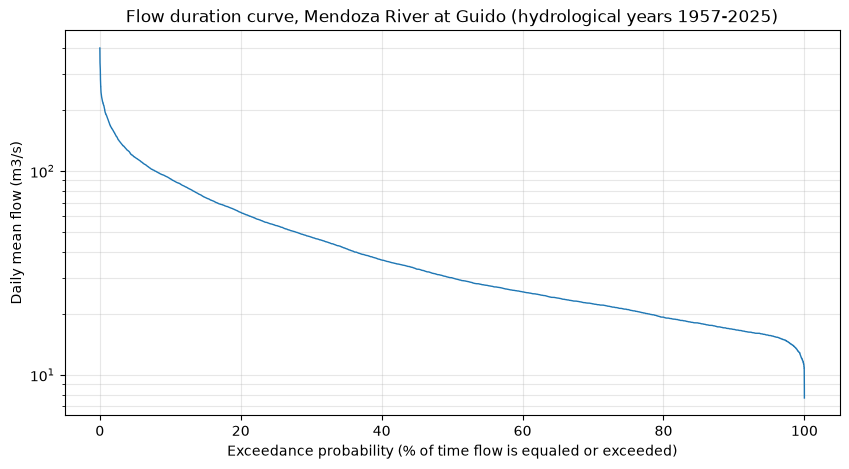

In [8]:
# Filter and keep only in q_hy the days from the 69 full years, to be consistent with D6:
q_hy = q[(hydro_year >= 1957) & (hydro_year <= 2025)]

# Sort in descending order and reset the index:
q_sorted = q_hy.sort_values(ascending=False).reset_index(drop=True) #drop=True replaces the dates for positions: 0,1,2,..

# Calculate the exceedance probability (Weibull formula).
exceedance = 100 * (q_sorted.index + 1) / (len(q_sorted) + 1) # M: is the position + 1, because Python starts counting at 0:

# Calculate the Qp values : quantiles
for p in [10, 30, 40, 50, 90, 95]:
    print(f"Q{p}: {q_hy.quantile(1 - p/100):.1f} m3/s") # we use (1 - p/100) because “quantile” returns the value at the x% percentile below, and we want the value above x% 

Q10 = q_hy.quantile(1 - 10/100)
Q90 = q_hy.quantile(1 -90/100)
print("Q10 is ", round(Q10/Q90,1),  "times as big as Q90")

# Plot exceedance probability (x-axis, %) against discharge (y-axis, m³/s)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(exceedance, q_sorted, linewidth=1)   # x: % of time exceeded, y: flow
ax.set_yscale("log")                         # log scale: low winter flows and summer peaks both visible
ax.set_xlabel("Exceedance probability (% of time flow is equaled or exceeded)")
ax.set_ylabel("Daily mean flow (m3/s)")
ax.set_title("Flow duration curve, Mendoza River at Guido (hydrological years 1957-2025)")
ax.grid(True, which="both", alpha=0.3)        
plt.show()

### Interpretation
1) The Q10/Q90 ratio of ≈ 5.5 indicates that Q10 is approximately 5.5 times greater than Q90: The Q10 value corresponds to the snowmelt season (which generates high flows), while the Q90 value corresponds to the winter season, characterized by a winter base flow; for this reason, the 5.5x ratio is, above all, seasonal.
Furthermore, it is worth noting that the FDC does not show the chronological sequence of flows (Searcy, 1959), since the values have been rearranged from highest to lowest. In other words, the probability of exceedance and the quantiles are derived from the FDC, while the persistence and sequence of dry years continue to be derived from the analysis presented in Section 1.6.

2) The candidate design flow rate falls between Q30 and Q40: approximately 110 to 146 days per year at full load with excess flow spilled.

3) Q90 is equivalent to 35% of the design flow rate (Q90/Q30) with one power-generating turbine, and 70% with two (Q90 / (Q30/2)). Considering that the minimum technical flow rate for a Francis-type turbine is approximately 50% of the nominal flow rate according to the National Technical University of Athens [https://www.itia.ntua.gr/el/getfile/2050/7/documents/06_SmallHydroSupplementary.pdf], the option of using two Francis-type turbines is attractive in terms of remaining above that minimum technical flow rate.
However, two units imply higher CAPEX and O&M than one unit of the same total capacity; whether the extra winter energy pays for it is to be verified once energy and CAPEX are modeled.

4) Another important parameter when discussing hydroelectric turbines is the head, which, in the case of a Francis turbine, ranges from 25 to 350 meters according to Tsuanyo, D., Amougou, B., Aziz, A. et al.  [https://jrenewables.springeropen.com/articles/10.1186/s40807-023-00072-1/tables/2] (The parameters of head, ecological flow, and costs have yet to be defined).